<a href="https://colab.research.google.com/github/vanessapeterka/a-sigla/blob/main/Vanessa_%20exerc%C3%ADcio_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
from datetime import datetime
import pandas as pd
import requests

# Converter datas para Unix Timestamp (segundos)
start_ts = int(datetime.strptime("2026-10-20 00:00:00", "%Y-%m-%d %H:%M:%S").timestamp())
end_ts = int(datetime.strptime("2026-10-27 00:00:00", "%Y-%m-%d %H:%M:%S").timestamp())

api_url = "https://simcosta.furg.br/api/intrans_data"
params = {
    "boiaID": 304,
    "type": "json",
    "time1": start_ts,
    "time2": end_ts,
    "params": "avg_water_level_arbitrary_zero,water_level_arbitrary_zero,water_distance_instrument_zero,avg_water_distance_instrument_zero"
}

try:
    response = requests.get(api_url, params=params, timeout=20)
    response.raise_for_status()

    data = response.json()
    df = pd.DataFrame(data)

    print(f"Sucesso! {len(df)} registros carregados.")
    print("Colunas retornadas:", df.columns.tolist())
    display(df.head())

except Exception as e:
    print(f"Ocorreu um erro: {e}")

Sucesso! 9993 registros carregados.
Colunas retornadas: ['timestamp', 'YEAR', 'MONTH', 'DAY', 'HOUR', 'MINUTE', 'SECOND', 'water_level_arbitrary_zero', 'avg_water_level_arbitrary_zero', 'water_distance_instrument_zero', 'avg_water_distance_instrument_zero']


,timestamp,YEAR,MONTH,DAY,HOUR,MINUTE,SECOND,water_level_arbitrary_zero,avg_water_level_arbitrary_zero,water_distance_instrument_zero,avg_water_distance_instrument_zero
0,2026-10-20T00:00:00.000Z,2026,10,20,0,0,0,12.579,12.590,2.421,2.410
1,2026-10-20T00:01:00.000Z,2026,10,20,0,1,0,12.582,12.579,2.418,2.421
2,2026-10-20T00:02:00.000Z,2026,10,20,0,2,0,12.574,12.587,2.426,2.413
3,2026-10-20T00:03:00.000Z,2026,10,20,0,3,0,12.585,12.567,2.415,2.433
4,2026-10-20T00:04:00.000Z,2026,10,20,0,4,0,12.552,12.580,2.448,2.420


In [14]:
# Verificação rápida dos metadados diretamente no DataFrame
print("Colunas de nível:", [c for c in df.columns if 'water' in c])
print("Exemplo de timestamp (fuso UTC indicado pelo 'Z'):", df['timestamp'].iloc[0])
print("Soma nível arbitrário + distância do instrumento (m):",
      (df['water_level_arbitrary_zero'] + df['water_distance_instrument_zero']).iloc[0])

Colunas de nível: ['water_level_arbitrary_zero', 'avg_water_level_arbitrary_zero', 'water_distance_instrument_zero', 'avg_water_distance_instrument_zero']
Exemplo de timestamp (fuso UTC indicado pelo 'Z'): 2026-10-20T00:00:00.000Z
Soma nível arbitrário + distância do instrumento (m): 15.0


In [15]:
import pandas as pd

# 1. Converter a coluna timestamp para datetime e ordenar
df['dt'] = pd.to_datetime(df['timestamp'])
df_ordenado = df.sort_values('dt').reset_index(drop=True)

# 2. Calcular os intervalos de tempo (diferença entre registros consecutivos)
diffs = df_ordenado['dt'].diff()

# --- Frequência de amostragem ---
freq_modal = diffs.mode()[0]
print(f"Frequência de amostragem predominante (moda): {freq_modal}")
print("\nDistribuição dos intervalos encontrados (Top 5):")
print(diffs.value_counts().head(5))

# --- Horários duplicados ---
duplicados = df_ordenado[df_ordenado.duplicated(subset=['dt'], keep=False)]
print(f"\nTotal de registros com horários duplicados: {len(duplicados)}")
if not duplicados.empty:
    display(duplicados[['timestamp', 'water_level_arbitrary_zero', 'avg_water_level_arbitrary_zero']].head(10))

# --- Duração das maiores lacunas (gaps > frequência normal) ---
lacunas = df_ordenado[diffs > freq_modal].copy()
lacunas['inicio_lacuna'] = df_ordenado['dt'].shift(1).loc[lacunas.index]
lacunas['fim_lacuna'] = lacunas['dt']
lacunas['duracao'] = diffs.loc[lacunas.index]

print(f"\nTotal de lacunas encontradas (> {freq_modal}): {len(lacunas)}")
print("Top 5 maiores lacunas:")
display(lacunas[['inicio_lacuna', 'fim_lacuna', 'duracao']].sort_values(by='duracao', ascending=False).head(5))

Frequência de amostragem predominante (moda): 0 days 00:01:00

Distribuição dos intervalos encontrados (Top 5):
dt
0 days 00:01:00    9904
0 days 00:02:00      88
Name: count, dtype: int64

Total de registros com horários duplicados: 0

Total de lacunas encontradas (> 0 days 00:01:00): 88
Top 5 maiores lacunas:


,inicio_lacuna,fim_lacuna,duracao
97,2026-10-20 01:36:00+00:00,2026-10-20 01:38:00+00:00,0 days 00:02:00
225,2026-10-20 03:45:00+00:00,2026-10-20 03:47:00+00:00,0 days 00:02:00
6674,2026-10-24 16:17:00+00:00,2026-10-24 16:19:00+00:00,0 days 00:02:00
6584,2026-10-24 14:46:00+00:00,2026-10-24 14:48:00+00:00,0 days 00:02:00
6512,2026-10-24 13:33:00+00:00,2026-10-24 13:35:00+00:00,0 days 00:02:00


### Metadados e Parametrização dos Dados (Estação DHN - ID 304)

#### 1. Variáveis e Unidades
* **Variável Principal de Nível:** `water_level_arbitrary_zero` e `avg_water_level_arbitrary_zero`.
* **Variável Auxiliar de Distância:** `water_distance_instrument_zero` e `avg_water_distance_instrument_zero`.
* **Unidade de Medida:** **Metros (m)**.
  * *Evidência:* A soma das colunas de nível e distância resulta exatamente em um valor constante de **15.0 m** em todos os registros (conforme verificado no código anterior), o que corresponde à distância física fixa do sensor até o zero arbitrário.

#### 2. Fuso Horário
* **Fuso:** **UTC (Universal Time Coordinated)**.
* **Origem da Informação:** Representado pela letra **'Z'** (Zulu Time) no final das strings de data/hora (ex: `2026-10-20T00:00:00.000Z`) presentes na coluna `timestamp` fornecida diretamente pela API do SiMCosta.

#### 3. Referência Vertical
* **Referência:** **Zero Arbitrário** (local da estação).
* **Origem da Informação:** O nome da própria variável (`arbitrary_zero`) explicita que os dados não estão referenciados a um datum oficial absoluto (como o Imbituba ou Santana), mas sim a um referencial vertical de nível (zero) definido arbitrariamente para a operação do sensor nesta estação física.

1. Frequência de Amostragem
Frequência predominante (Moda): 1 minuto (0 days 00:01:00).
Distribuição dos intervalos:
9.904 registros possuem exatamente 1 minuto de intervalo em relação ao registro anterior.
88 registros possuem 2 minutos de intervalo (indicando pequenas falhas pontuais de transmissão ou leituras não registradas).
2. Horários Duplicados
Total de registros duplicados: 0 (nenhum horário duplicado foi encontrado na série temporal analisada, garantindo a unicidade de cada registro).
3. Duração das Maiores Lacunas (Gaps)
Total de lacunas encontradas (> 1 min): 88 lacunas.
Duração máxima das lacunas: Todas as 88 lacunas têm a duração exata de 2 minutos (ou seja, apenas 1 registro perdido consecutivamente em cada ocorrência). Não foram identificad

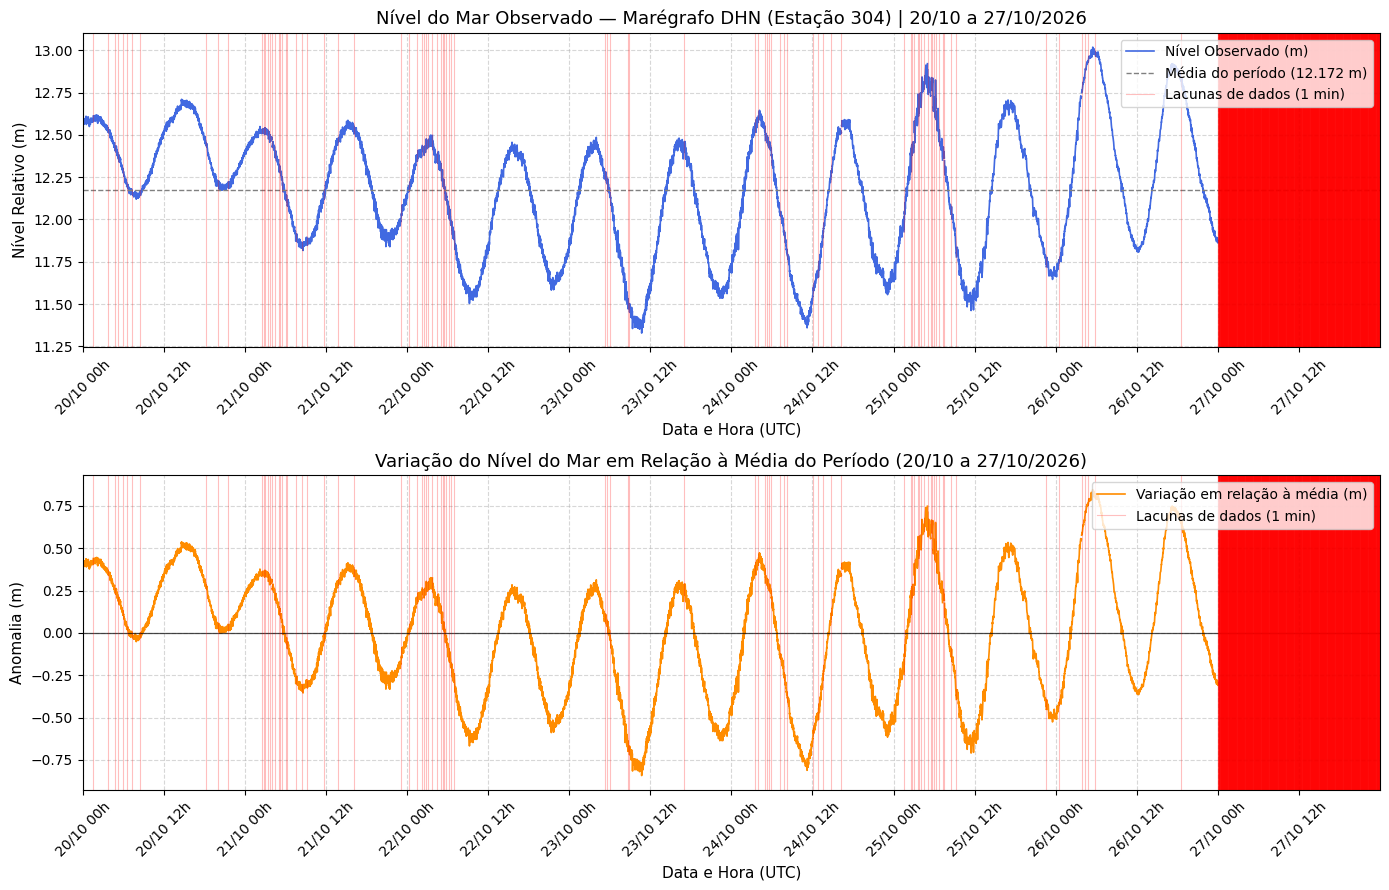

In [17]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

# 1. Filtrar estritamente de 20/10/2026 00:00 até 27/10/2026 23:59 e reindexar (1 min)
df_plot = df.copy()
df_plot['dt'] = pd.to_datetime(df_plot['timestamp'])
df_plot = df_plot.sort_values('dt').set_index('dt')

inicio = pd.Timestamp('2026-10-20 00:00:00', tz='UTC')
fim = pd.Timestamp('2026-10-27 23:59:00', tz='UTC')

grade_completa = pd.date_range(start=inicio, end=fim, freq='1min')
df_regular = df_plot.reindex(grade_completa)

# 2. Definir a variável de nível observado e calcular a anomalia (variação em relação à média)
nivel_obs = pd.to_numeric(df_regular['avg_water_level_arbitrary_zero'], errors='coerce')
media_periodo = nivel_obs.mean()
variacao_media = nivel_obs - media_periodo

# 3. Criar os dois gráficos
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9))

# Gráfico 1: Nível observado
ax1.plot(df_regular.index, nivel_obs, color='royalblue', linewidth=1.2, label='Nível Observado (m)')
ax1.axhline(media_periodo, color='gray', linestyle='--', linewidth=1, label=f'Média do período ({media_periodo:.3f} m)')
ax1.set_title('Nível do Mar Observado — Marégrafo DHN (Estação 304) | 20/10 a 27/10/2026', fontsize=13)
ax1.set_ylabel('Nível Relativo (m)', fontsize=11)
ax1.set_xlabel('Data e Hora (UTC)', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)

# Gráfico 2: Variações em relação à média (anomalia)
ax2.plot(df_regular.index, variacao_media, color='darkorange', linewidth=1.2, label='Variação em relação à média (m)')
ax2.axhline(0, color='black', linestyle='-', linewidth=0.9, alpha=0.7)
ax2.set_title('Variação do Nível do Mar em Relação à Média do Período (20/10 a 27/10/2026)', fontsize=13)
ax2.set_ylabel('Anomalia (m)', fontsize=11)
ax2.set_xlabel('Data e Hora (UTC)', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)

# Destacar visualmente as lacunas (gaps) nos dois gráficos
lacunas_idx = df_regular.index[nivel_obs.isna()]
for i, t_gap in enumerate(lacunas_idx):
    lbl = 'Lacunas de dados (1 min)' if i == 0 else None
    ax1.axvline(t_gap, color='red', alpha=0.25, linewidth=0.8, label=lbl)
    ax2.axvline(t_gap, color='red', alpha=0.25, linewidth=0.8, label=lbl)

# Travar o eixo X exatamente entre 20/10 e 27/10 e formatar as datas
for ax in (ax1, ax2):
    ax.set_xlim(inicio, fim)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d/%m %Hh'))
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=12))
    ax.tick_params(axis='x', rotation=45)
    ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [ ]:
from scipy.signal import find_peaks
import numpy as np

# Remover NaNs para evitar problemas na detecção de picos
df_limpo = df_regular.dropna(subset=['avg_water_level_arbitrary_zero']).copy()

# Encontrar os índices dos picos (preamares)
# Como a maré semidiurna tem ciclos de ~12h (720 min), definimos uma distância mínima de 500 min entre picos
picos_indices, _ = find_peaks(df_limpo['avg_water_level_arbitrary_zero'], distance=500, prominence=0.1)

preamares = df_limpo.iloc[picos_indices].copy()
preamares['Dia'] = preamares.index.strftime('%d/%m/%Y')
preamares['Hora_UTC'] = preamares.index.strftime('%H:%M')

# Mostrar os picos identificados por dia
tabela_preamares = preamares[['Dia', 'Hora_UTC', 'avg_water_level_arbitrary_zero']].rename(
    columns={'avg_water_level_arbitrary_zero': 'Altura_Preamar_m'}
)

print("--- Preamares Identificadas Programaticamente ---")
display(tabela_preamares)

### Análise de Preamares

#### 1. Quantas preamares por dia?
* **Duas preamares por dia** (regime semidiurno). Isso é comprovado pela tabela acima, que mostra dois horários de pico diários espaçados por aproximadamente 12 horas.

#### 2. A altura muda ao longo da semana?
* **Sim**. Há uma variação clara de amplitude. No dia 23/10 as preamares atingiram máximas de cerca de 12,47 m, enquanto no dia 26/10 o nível máximo subiu para 13,01 m, indicando a transição para uma maré de sizígia.